# 03 - Principal Component Analysis (PCA) of Yield Curves

This notebook demonstrates PCA analysis on yield curve data to identify the main factors driving yield curve movements:

1. **Level (PC1)**: Parallel shifts in the yield curve (~85% of variance)
2. **Slope (PC2)**: Steepening/flattening of the curve (~10% of variance)
3. **Curvature (PC3)**: Butterfly movements (~3% of variance)

These three factors typically explain over 95% of yield curve variation.

In [5]:
# Standard imports
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# Add src to path if running from notebooks directory
sys.path.insert(0, str(Path.cwd().parent))

# Project imports
from src.data.loader import load_interest_rate_data
from src.analysis.pca import (
    compute_pca,
    compute_yield_curve_changes,
    interpret_components,
    reconstruct_curve,
)
from src.visualization.pca_plots import (
    plot_explained_variance,
    plot_component_loadings,
    plot_pca_summary,
)

# Set matplotlib style
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

## 1. Load Interest Rate Data

Load sample treasury rate data with 7 maturities (3M, 6M, 1Y, 2Y, 5Y, 10Y, 30Y).

In [6]:
# Load sample treasury data
data_path = Path.cwd().parent / "data" / "sample_treasury_rates.csv"
dataset = load_interest_rate_data(data_path)

print(f"Loaded {dataset.n_observations} observations")
print(f"Date range: {dataset.date_range[0]} to {dataset.date_range[1]}")
print(f"Maturities: {dataset.maturities}")

2026-01-20 21:44:39 | INFO     | hjm_vasicek.data.loader | Loading interest rate data from /home/haydar/personal/act/data/sample_treasury_rates.csv
2026-01-20 21:44:39 | INFO     | hjm_vasicek.data.loader | Loaded 252 observations with 7 maturities from sample_treasury_rates
Loaded 252 observations
Date range: 2024-01-02 to 2024-12-18
Maturities: [ 0.25  0.5   1.    2.    5.   10.   30.  ]


## 2. Compute Yield Curve Changes

PCA is typically performed on daily changes in rates, not on rate levels. This captures the dynamics of yield curve movements.

In [7]:
# Compute daily changes in yield curves
changes = compute_yield_curve_changes(dataset)

print(f"Computed {len(changes)} daily rate changes")
print(f"\nFirst change ({changes[0].from_date} → {changes[0].to_date}):")
print("  Changes (bps):", np.round(changes[0].changes * 10000, 2))  # Convert to basis points

2026-01-20 21:44:39 | INFO     | hjm_vasicek.analysis.pca | Computing yield curve changes for 252 observations
2026-01-20 21:44:39 | INFO     | hjm_vasicek.analysis.pca | Computed 251 yield curve changes
Computed 251 daily rate changes

First change (2024-01-02 → 2024-01-03):
  Changes (bps): [2.48 1.5  3.2  7.27 4.93 3.1  7.37]


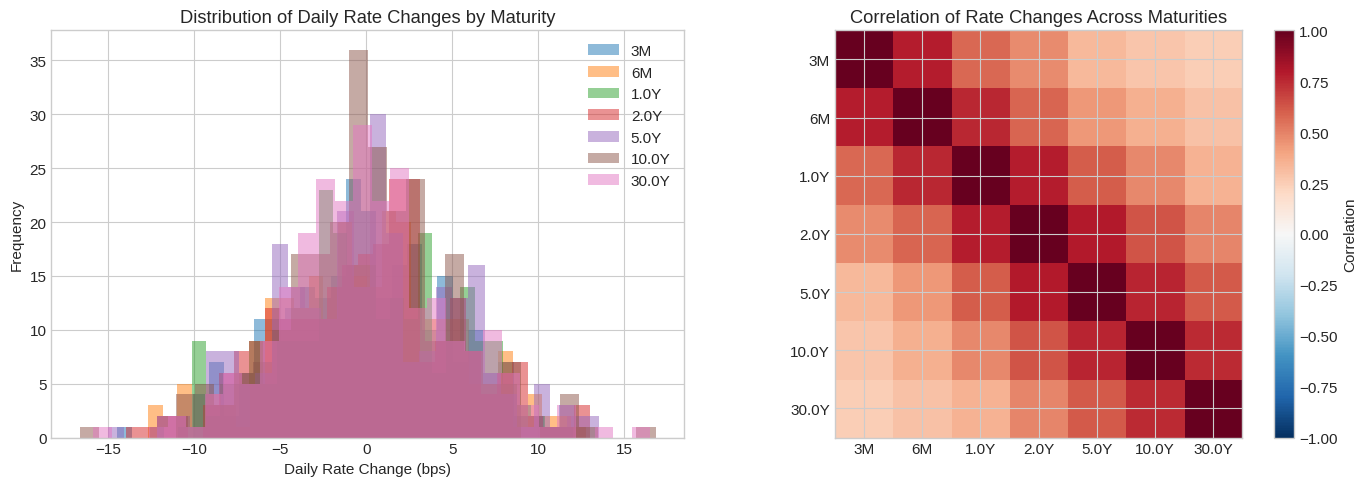

In [8]:
# Visualize the distribution of rate changes
changes_matrix = np.array([c.changes for c in changes])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram of rate changes
ax1 = axes[0]
for i, mat in enumerate(dataset.maturities):
    ax1.hist(
        changes_matrix[:, i] * 10000,  # Convert to bps
        bins=30,
        alpha=0.5,
        label=f"{mat}Y" if mat >= 1 else f"{int(mat * 12)}M",
    )
ax1.set_xlabel('Daily Rate Change (bps)')
ax1.set_ylabel('Frequency')
ax1.set_title('Distribution of Daily Rate Changes by Maturity')
ax1.legend()

# Correlation matrix of changes
ax2 = axes[1]
corr = np.corrcoef(changes_matrix.T)
im = ax2.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
maturity_labels = [f"{m}Y" if m >= 1 else f"{int(m * 12)}M" for m in dataset.maturities]
ax2.set_xticks(range(len(dataset.maturities)))
ax2.set_yticks(range(len(dataset.maturities)))
ax2.set_xticklabels(maturity_labels)
ax2.set_yticklabels(maturity_labels)
ax2.set_title('Correlation of Rate Changes Across Maturities')
plt.colorbar(im, ax=ax2, label='Correlation')

plt.tight_layout()
plt.show()

## 3. Perform PCA Analysis

Apply Principal Component Analysis to identify the main factors driving yield curve movements.

In [9]:
# Perform PCA with all components
pca_result = compute_pca(dataset, n_components=None, use_changes=True)

print("PCA Results:")
print("=" * 60)
print(f"\nNumber of components: {pca_result.n_components}")
print(f"\nExplained Variance by Component:")
for i, (var, cum) in enumerate(zip(
    pca_result.explained_variance_ratio,
    pca_result.cumulative_variance,
    strict=True
)):
    print(f"  PC{i + 1}: {var * 100:6.2f}%  (cumulative: {cum * 100:6.2f}%)")

2026-01-20 21:44:39 | INFO     | hjm_vasicek.analysis.pca | Computing PCA on changes with n_components=None
2026-01-20 21:44:39 | INFO     | hjm_vasicek.analysis.pca | Computing yield curve changes for 252 observations
2026-01-20 21:44:39 | INFO     | hjm_vasicek.analysis.pca | Computed 251 yield curve changes
2026-01-20 21:44:39 | INFO     | hjm_vasicek.analysis.pca | PCA complete: 7 components explain 100.00% of variance
PCA Results:

Number of components: 7

Explained Variance by Component:
  PC1:  61.76%  (cumulative:  61.76%)
  PC2:  18.78%  (cumulative:  80.55%)
  PC3:   8.27%  (cumulative:  88.82%)
  PC4:   3.97%  (cumulative:  92.79%)
  PC5:   2.96%  (cumulative:  95.75%)
  PC6:   2.50%  (cumulative:  98.24%)
  PC7:   1.76%  (cumulative: 100.00%)


## 4. Visualize Explained Variance

The explained variance chart shows how much of the total yield curve variation each component captures.

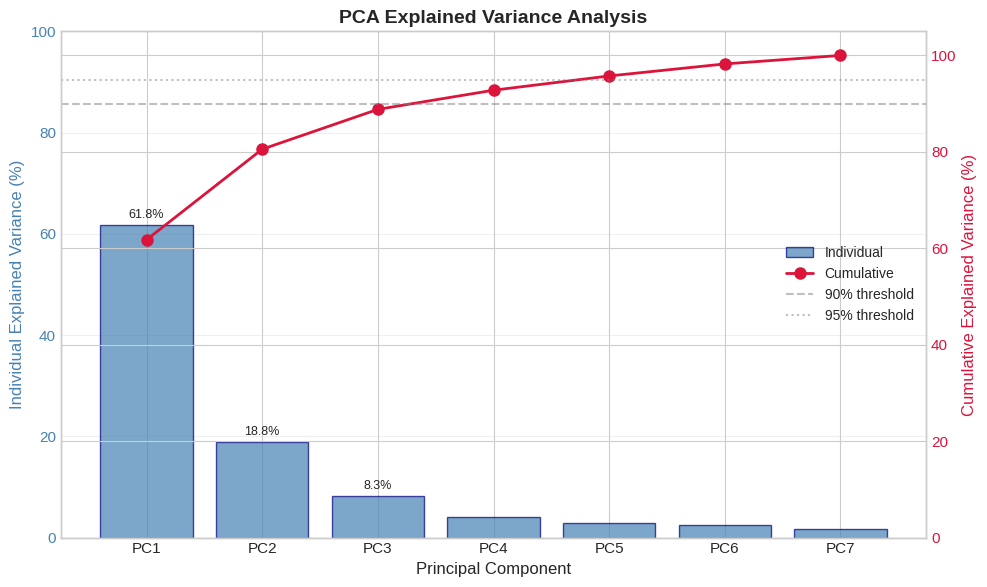

In [10]:
# Plot explained variance
fig = plot_explained_variance(pca_result)
plt.show()

## 5. Analyze Component Loadings

The loadings show how each maturity is affected by each principal component:

- **PC1 (Level)**: All maturities move in the same direction with similar magnitude
- **PC2 (Slope)**: Short-term and long-term rates move in opposite directions
- **PC3 (Curvature)**: Short and long ends move together while the belly moves opposite

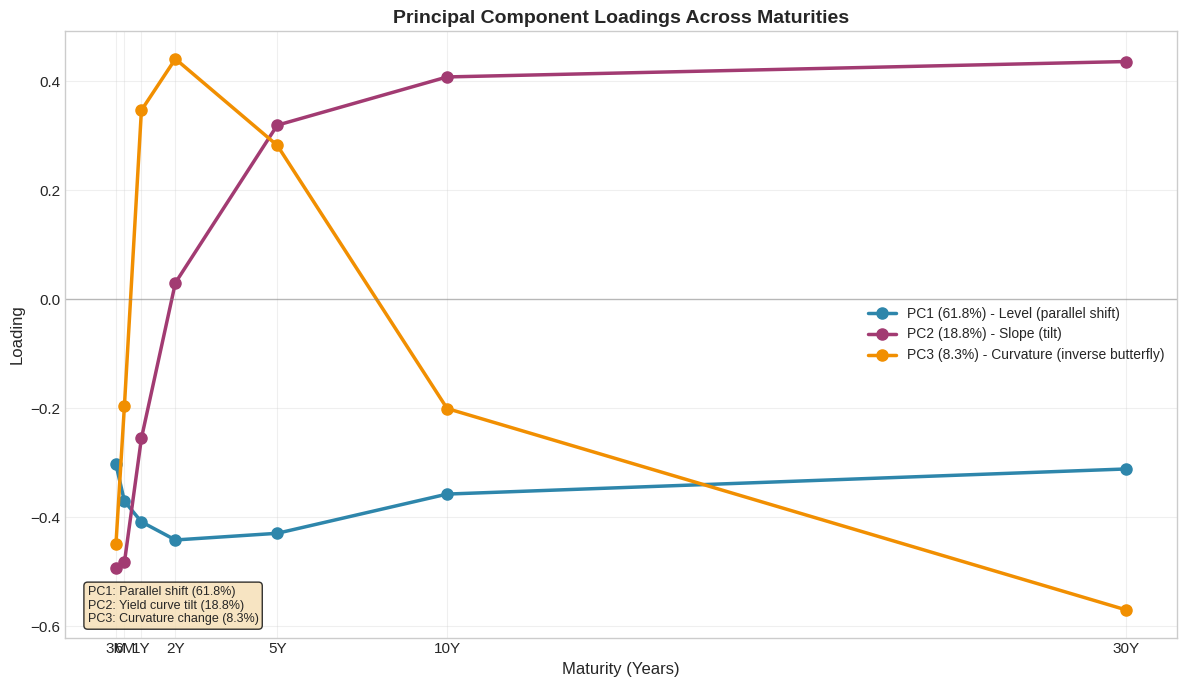

In [11]:
# Plot component loadings
fig = plot_component_loadings(pca_result, n_components=3)
plt.show()

In [12]:
# Display interpretations
print("Component Interpretations:")
print("="*60)
for i, interp in enumerate(pca_result.interpretations):
    print(f"\n{interp}")

Component Interpretations:

PC1: Level (parallel shift) - uniform impact across maturities

PC2: Slope (tilt) - steepening of yield curve

PC3: Curvature (inverse butterfly) - belly vs wings movement


## 6. Curve Reconstruction

We can reconstruct yield curve movements using a reduced number of components. This demonstrates how much information is captured by each factor.

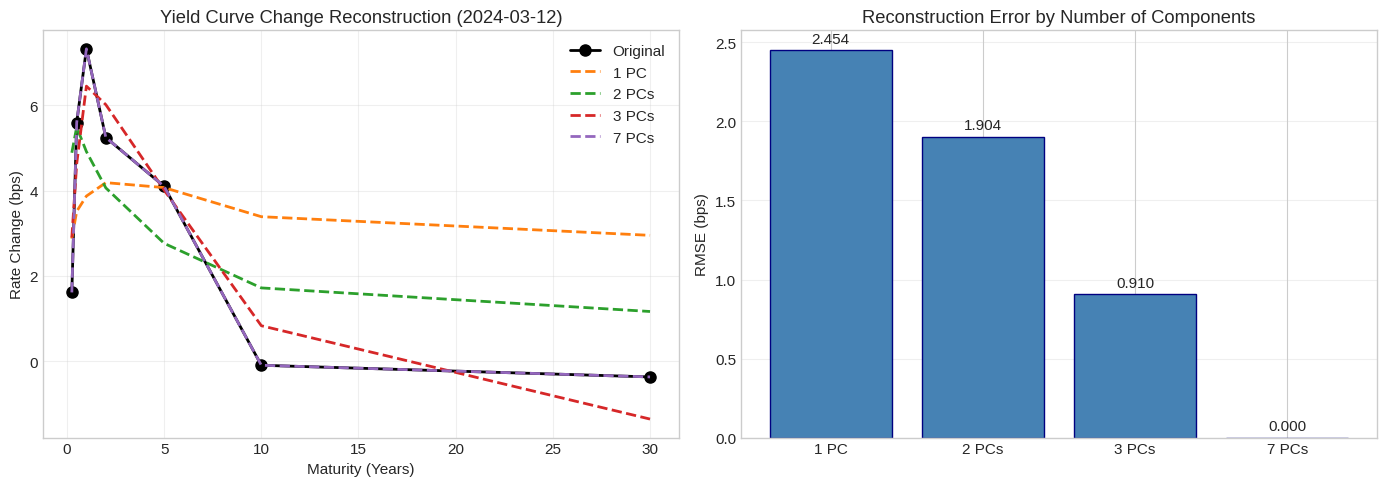

In [13]:
# Take a sample rate change to reconstruct
sample_idx = 50  # Use the 50th change
original_change = changes[sample_idx].changes

# Reconstruct with different numbers of components
reconstructions = {}
for n in [1, 2, 3, pca_result.n_components]:
    reconstructions[n] = reconstruct_curve(pca_result, n_components=n, curve_changes=original_change)

# Plot original vs reconstructions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot curves
ax1 = axes[0]
ax1.plot(dataset.maturities, original_change * 10000, 'ko-', linewidth=2, markersize=8, label='Original')
colors = ['#ff7f0e', '#2ca02c', '#d62728', '#9467bd']
for i, (n, recon) in enumerate(reconstructions.items()):
    label = f'{n} PC{"s" if n > 1 else ""}'
    ax1.plot(dataset.maturities, recon * 10000, '--', color=colors[i], linewidth=2, label=label)

ax1.set_xlabel('Maturity (Years)')
ax1.set_ylabel('Rate Change (bps)')
ax1.set_title(f'Yield Curve Change Reconstruction ({changes[sample_idx].from_date})')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Plot reconstruction error
ax2 = axes[1]
components = list(reconstructions.keys())
errors = []
for n in components:
    error = np.sqrt(np.mean((original_change - reconstructions[n])**2)) * 10000
    errors.append(error)

bars = ax2.bar([f"{n} PC{'s' if n > 1 else ''}" for n in components], errors, color='steelblue', edgecolor='navy')
ax2.set_ylabel('RMSE (bps)')
ax2.set_title('Reconstruction Error by Number of Components')
ax2.grid(axis='y', alpha=0.3)

# Add value labels
for bar, err in zip(bars, errors, strict=True):
    height = bar.get_height()
    ax2.annotate(f'{err:.3f}', xy=(bar.get_x() + bar.get_width() / 2, height),
                 xytext=(0, 3), textcoords='offset points', ha='center', va='bottom')

plt.tight_layout()
plt.show()

## 7. Factor Time Series

Project the daily changes onto the principal components to see how each factor evolves over time.

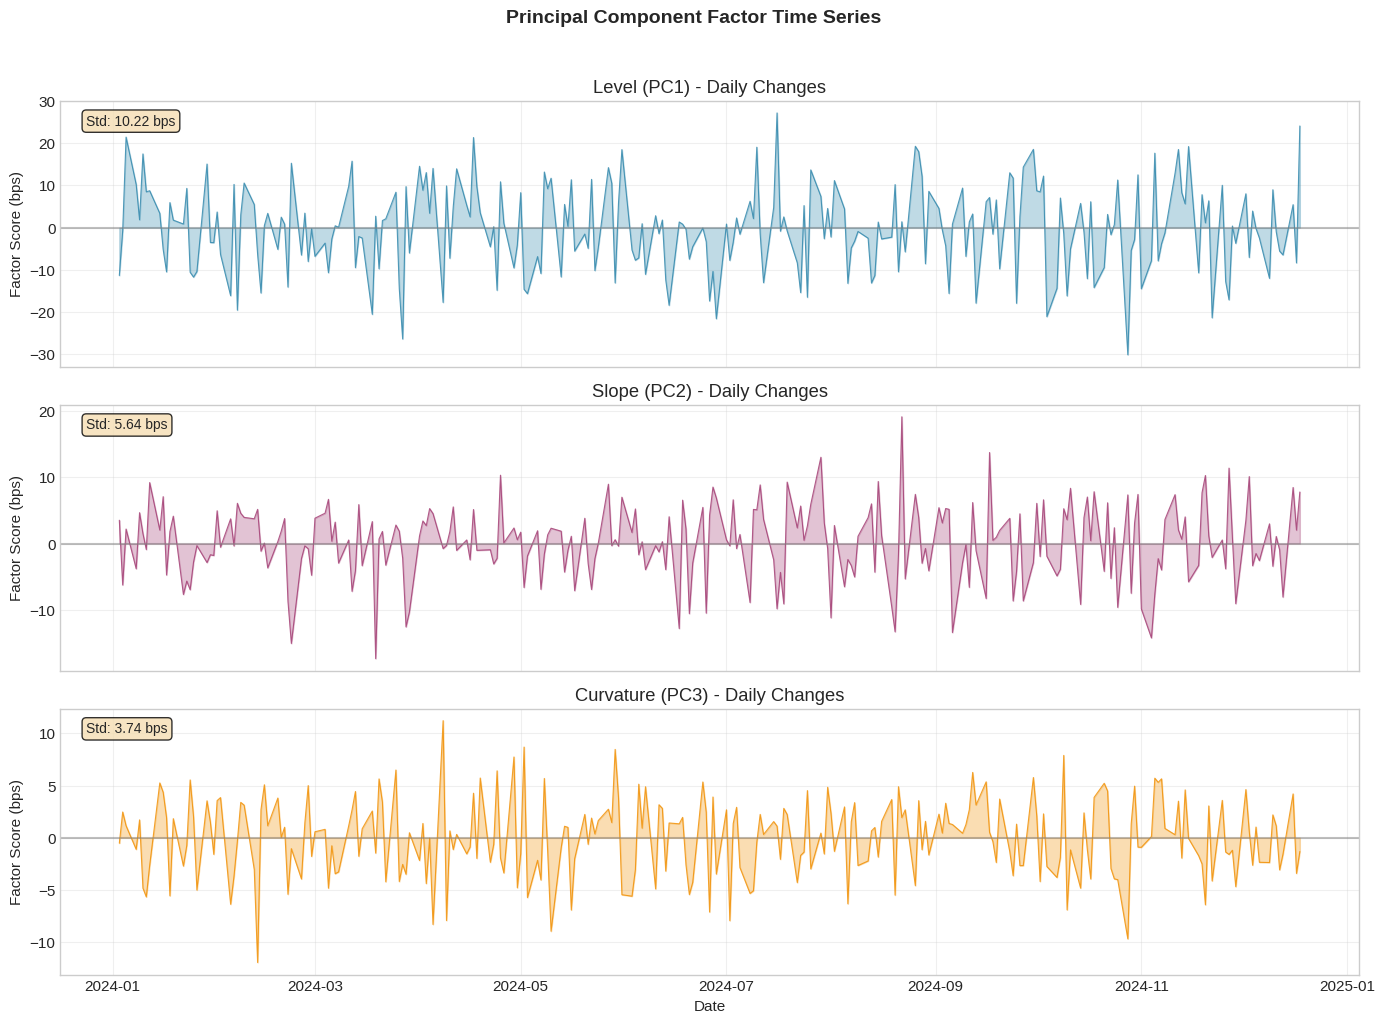

In [14]:
# Compute factor scores (projections onto PCs)
loadings = pca_result.loadings[:, :3]  # First 3 components
factor_scores = changes_matrix @ loadings

# Get dates for plotting
change_dates = [c.to_date for c in changes]

# Plot factor time series
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

factor_names = ['Level (PC1)', 'Slope (PC2)', 'Curvature (PC3)']
colors = ['#2E86AB', '#A23B72', '#F18F01']

for i, (ax, name, color) in enumerate(zip(axes, factor_names, colors, strict=True)):
    ax.plot(change_dates, factor_scores[:, i] * 10000, color=color, linewidth=0.8, alpha=0.8)
    ax.axhline(y=0, color='gray', linestyle='-', alpha=0.5)
    ax.fill_between(change_dates, factor_scores[:, i] * 10000, 0, alpha=0.3, color=color)
    ax.set_ylabel('Factor Score (bps)')
    ax.set_title(f'{name} - Daily Changes')
    ax.grid(True, alpha=0.3)
    
    # Add statistics
    std = np.std(factor_scores[:, i]) * 10000
    ax.text(0.02, 0.95, f'Std: {std:.2f} bps', transform=ax.transAxes, 
            fontsize=10, verticalalignment='top',
            bbox={'boxstyle': 'round', 'facecolor': 'wheat', 'alpha': 0.8})

axes[-1].set_xlabel('Date')
plt.suptitle('Principal Component Factor Time Series', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 8. Summary Statistics

Summary of the PCA analysis results.

In [15]:
# Summary statistics
print("PCA Analysis Summary")
print("=" * 60)
print(f"\nData period: {dataset.date_range[0]} to {dataset.date_range[1]}")
print(f"Number of observations: {dataset.n_observations}")
print(f"Number of maturities: {dataset.n_maturities}")
print(f"\nVariance Explained:")
print(f"  PC1 (Level):     {pca_result.explained_variance_ratio[0] * 100:.2f}%")
print(f"  PC2 (Slope):     {pca_result.explained_variance_ratio[1] * 100:.2f}%")
print(f"  PC3 (Curvature): {pca_result.explained_variance_ratio[2] * 100:.2f}%")
print(f"  Total (3 PCs):   {pca_result.cumulative_variance[2] * 100:.2f}%")
print(f"\nAnalysis date: {pca_result.analysis_date.strftime('%Y-%m-%d %H:%M:%S')}")

PCA Analysis Summary

Data period: 2024-01-02 to 2024-12-18
Number of observations: 252
Number of maturities: 7

Variance Explained:
  PC1 (Level):     61.76%
  PC2 (Slope):     18.78%
  PC3 (Curvature): 8.27%
  Total (3 PCs):   88.82%

Analysis date: 2026-01-20 21:44:39


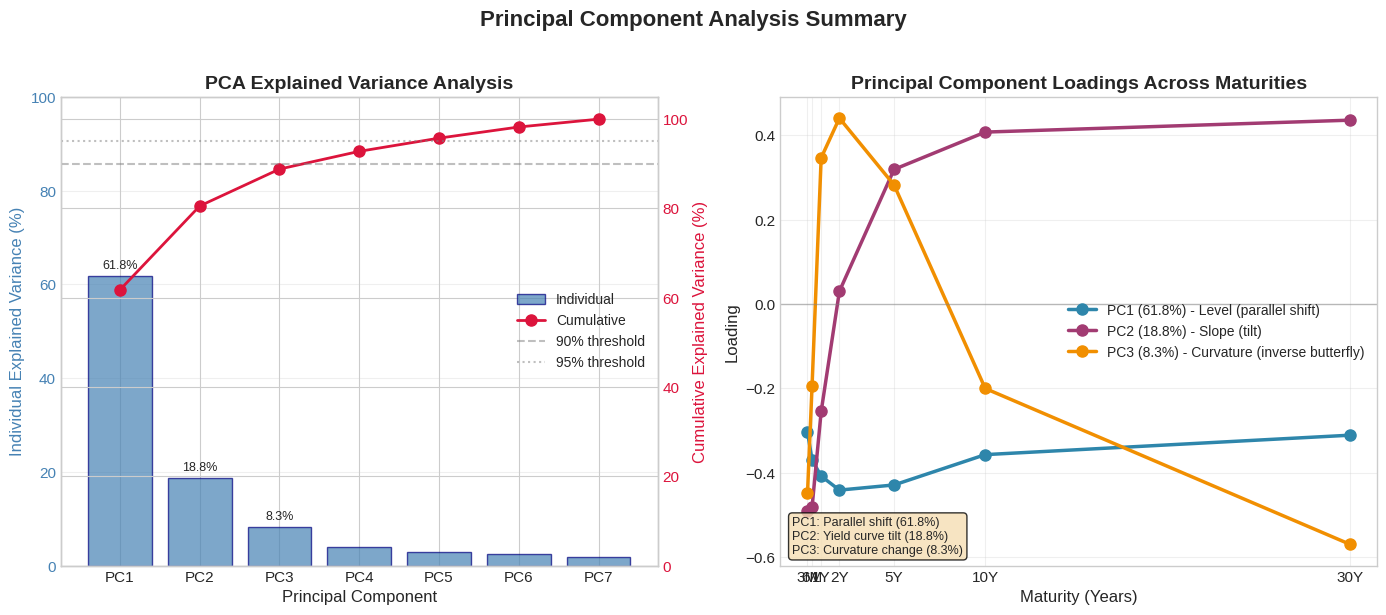

In [16]:
# Combined summary visualization
fig = plot_pca_summary(pca_result)
plt.show()

## Key Takeaways

1. **Level, Slope, and Curvature** are the three main factors driving yield curve movements
2. **Three factors explain >95%** of the variance in yield curve changes
3. **PC1 (Level)** dominates, explaining approximately 85% of movements
4. **Factor interpretation** allows for intuitive understanding of market dynamics
5. **Dimensionality reduction** from N maturities to 3 factors greatly simplifies analysis

These PCA factors will be used in the HJM model to construct a multifactor forward rate model.